● Write a program to denoise the input image using adaptive median filter.
Input the initial window size and maximum size of window (Smax) from
the user. Compare the performance of median filter and adaptive median
filter, using the PSNR values.
● Write a program to threshold the image using Otsu's global threshold for
segmentation of input gray scale image.

Saving Spider Lily.jpeg to Spider Lily (3).jpeg
Image loaded successfully.
Image shape: (1307, 736)
Enter initial window size (odd, e.g. 3): 3
Enter maximum window size (odd, e.g. 7): 7

Applying Adaptive Median Filter...


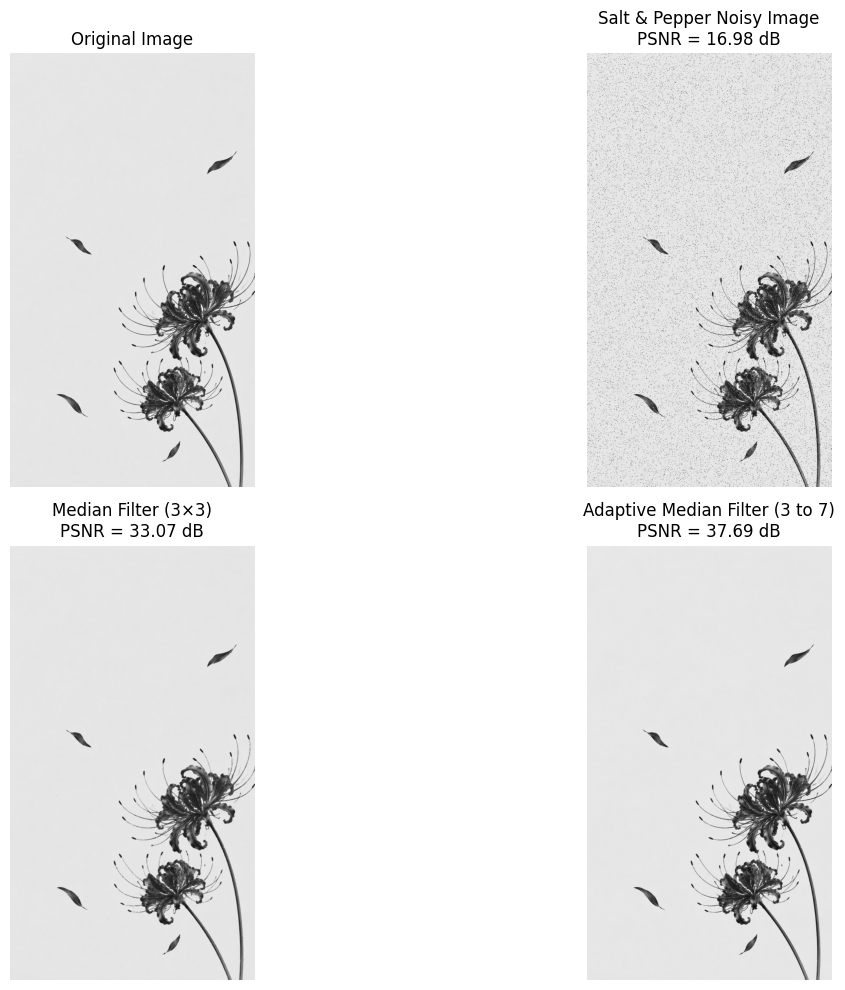


========== PSNR COMPARISON ==========
Noisy Image            : 16.98 dB
Median Filter          : 33.07 dB
Adaptive Median Filter : 37.69 dB


In [4]:
# ==========================================================
# ADAPTIVE MEDIAN FILTER + MEDIAN FILTER + PSNR
# ==========================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# ----------------------------------------------------------
# 1. Upload image
# ----------------------------------------------------------
uploaded = files.upload()
filename = next(iter(uploaded))

img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

if img is None:
    raise ValueError("Image could not be loaded.")

print("Image loaded successfully.")
print("Image shape:", img.shape)


# ----------------------------------------------------------
# 2. Add Salt and Pepper Noise
# ----------------------------------------------------------
noise_probability = 0.05

noisy = img.copy()

random = np.random.random(img.shape)

# Salt
noisy[random < noise_probability / 2] = 255

# Pepper
noisy[random > 1 - noise_probability / 2] = 0


# ----------------------------------------------------------
# 3. Adaptive Median Filter
# ----------------------------------------------------------
def adaptive_median_filter(image, Smin, Smax):

    # Convert to int16 to prevent uint8 overflow
    image = image.astype(np.int16)

    padding = Smax // 2

    padded = cv2.copyMakeBorder(
        image,
        padding,
        padding,
        padding,
        padding,
        cv2.BORDER_REFLECT
    )

    output = np.zeros(image.shape, dtype=np.uint8)

    rows, cols = image.shape

    for i in range(rows):
        for j in range(cols):

            window_size = Smin

            while window_size <= Smax:

                half = window_size // 2

                r = padding + i
                c = padding + j

                window = padded[
                    r-half:r+half+1,
                    c-half:c+half+1
                ]

                # Convert values to normal integers
                Zmin = int(np.min(window))
                Zmax = int(np.max(window))
                Zmed = int(np.median(window))
                Zxy = int(padded[r, c])

                # -------------------------
                # Stage A
                # -------------------------
                A1 = Zmed - Zmin
                A2 = Zmed - Zmax

                if A1 > 0 and A2 < 0:

                    # -------------------------
                    # Stage B
                    # -------------------------
                    B1 = Zxy - Zmin
                    B2 = Zxy - Zmax

                    if B1 > 0 and B2 < 0:
                        output[i, j] = Zxy
                    else:
                        output[i, j] = Zmed

                    break

                else:
                    window_size += 2

            # If Smax is reached
            if window_size > Smax:
                output[i, j] = Zmed

    return output


# ----------------------------------------------------------
# 4. Input window sizes
# ----------------------------------------------------------
Smin = int(input("Enter initial window size (odd, e.g. 3): "))
Smax = int(input("Enter maximum window size (odd, e.g. 7): "))

# Check values
if Smin % 2 == 0 or Smax % 2 == 0:
    raise ValueError("Window sizes must be odd.")

if Smin > Smax:
    raise ValueError("Initial window size must be <= maximum window size.")

print("\nApplying Adaptive Median Filter...")
adaptive_result = adaptive_median_filter(noisy, Smin, Smax)


# ----------------------------------------------------------
# 5. Standard Median Filter
# ----------------------------------------------------------
median_result = cv2.medianBlur(noisy, Smin)


# ----------------------------------------------------------
# 6. PSNR
# ----------------------------------------------------------
def calculate_psnr(original, restored):

    original = original.astype(np.float64)
    restored = restored.astype(np.float64)

    mse = np.mean((original - restored) ** 2)

    if mse == 0:
        return float("inf")

    return 10 * np.log10((255 ** 2) / mse)


psnr_noisy = calculate_psnr(img, noisy)
psnr_median = calculate_psnr(img, median_result)
psnr_adaptive = calculate_psnr(img, adaptive_result)


# ----------------------------------------------------------
# 7. Display Results
# ----------------------------------------------------------
plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(noisy, cmap="gray")
plt.title(f"Salt & Pepper Noisy Image\nPSNR = {psnr_noisy:.2f} dB")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(median_result, cmap="gray")
plt.title(f"Median Filter ({Smin}×{Smin})\nPSNR = {psnr_median:.2f} dB")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(adaptive_result, cmap="gray")
plt.title(f"Adaptive Median Filter ({Smin} to {Smax})\nPSNR = {psnr_adaptive:.2f} dB")
plt.axis("off")

plt.tight_layout()
plt.show()


# ----------------------------------------------------------
# 8. PSNR Comparison
# ----------------------------------------------------------
print("\n========== PSNR COMPARISON ==========")
print(f"Noisy Image            : {psnr_noisy:.2f} dB")
print(f"Median Filter          : {psnr_median:.2f} dB")
print(f"Adaptive Median Filter : {psnr_adaptive:.2f} dB")